
# 43 量化计量经济学：回归、平稳性、协整与面板

> **本章要解决的问题**：同一张数据表，为什么有人跑出 t=5，有人跑出 t=0.8？两条价格都能回归出很高的 R²，哪一个才是伪回归？面板、工具变量、双重差分，各在补哪一个漏洞？

## 本章导读

前面四十多章大部分时间在“构造信号、评价信号”。这一章退一步，讲**怎么用数据验证一个结论**。同一个最小二乘，换一组标准误、换一种平稳性处理、换一个识别策略，结论可能完全相反：

1. OLS 与 HAC：系数是点估计，标准误才是可信度；
2. 单位根与 ADF：价格不平稳、收益才平稳，别拿水平值硬回归；
3. 协整与 Engle–Granger：两条随机漫步之间也可能有长期“橡皮筋”；
4. VAR 与 Granger：谁先动、谁跟着动，以及“预测性因果”不是“结构因果”；
5. 面板固定效应：把个体差异减掉，别把“公司好”当成“变量有效”；
6. IV / 2SLS 与 DID：想讲因果，先找到外生变动；
7. 模型诊断：残差、异方差、自相关、结构突变与样本外。

### 学习目标

- 能写出 OLS 的系数与标准误公式，并说明 HAC（Newey–West）在修正什么。
- 能对价格和收益做 ADF 检验，并解释“不拒绝单位根”到底意味着什么。
- 能用 Engle–Granger 两步法做协整检验，并从 AR(1) 系数算半衰期。
- 能区分“协整”和“高 R² 的伪回归”，各举一个数字例子。
- 能估一个 VAR、做 Granger 检验、读脉冲响应。
- 能用组内变换估面板固定效应，并解释混合 OLS 的偏误来源。
- 能写 2SLS 的两阶段估计和一阶段 F，并说明 DID 的平行趋势假设。
- 能列出一份回归结果交付前的诊断清单。

### 先修

第02章的期望、方差与假设检验；第08章的平稳性与 AR(1)；第04章的矩阵最小二乘；会 numpy 和 statsmodels。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="43 量化计量经济学：回归、平稳性、协整与面板" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>43 量化计量经济学：回归、平稳性、协整与面板｜知识图</title>
<desc>本章主线：OLS/HAC 看稳健标准误，ADF 判平稳，协整把两条价格绑成一条平稳价差。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a43" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao43" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag43" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">43</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">量化计量经济学：回归、平稳性、协整与面板</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：OLS/HAC 看稳健标准误，ADF 判平稳，协整把两条价格绑成一条平稳价差。</text>
<rect x="40" y="88" width="345" height="240" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<text x="54" y="108" font-size="10.5" fill="#1B3A5C" font-weight="bold">① OLS + HAC：系数与残差</text>
<path d="M 78 292 L 360 292" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag43)"/>
<path d="M 78 292 L 78 292" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag43)"/>
<path d="M 78 292 L 78 292" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag43)"/>
<path d="M 78 292 L 78 130" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag43)"/>
<text x="350" y="308" font-size="8.8" fill="#6E7B8B">x</text>
<text x="86" y="140" font-size="8.8" fill="#6E7B8B">r</text>
<line x1="95" y1="280" x2="355" y2="160" stroke="#E07B39" stroke-width="1.8" stroke-linecap="round"/>
<line x1="100" y1="272" x2="100" y2="277.7" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="100" cy="272" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="120" y1="258" x2="120" y2="268.5" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="120" cy="258" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="145" y1="264" x2="145" y2="256.9" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="145" cy="264" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="165" y1="244" x2="165" y2="247.7" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="165" cy="244" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="190" y1="232" x2="190" y2="236.2" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="190" cy="232" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="210" y1="238" x2="210" y2="226.9" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="210" cy="238" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="235" y1="215" x2="235" y2="215.4" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="235" cy="215" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="255" y1="208" x2="255" y2="206.2" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="255" cy="208" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="280" y1="200" x2="280" y2="194.6" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="280" cy="200" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="305" y1="186" x2="305" y2="183.1" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="305" cy="186" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="330" y1="176" x2="330" y2="171.5" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="330" cy="176" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<line x1="345" y1="168" x2="345" y2="164.6" stroke="#6E7B8B" stroke-width="0.9" stroke-linecap="round" opacity="0.7"/>
<circle cx="345" cy="168" r="2.6" fill="#1B3A5C" opacity="0.7"/>
<text x="88" y="160" font-size="9.2" fill="#1B3A5C">r = α + βx + ε</text>
<text x="200" y="160" font-size="8.8" fill="#6E7B8B">HAC：Newey–West 标准误</text>
<rect x="405" y="88" width="350" height="240" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<text x="419" y="108" font-size="10.5" fill="#1B3A5C" font-weight="bold">② 协整：两条价格 → 一条平稳价差</text>
<path d="M 425 200 L 453 194.5 L 481 189 L 509 183.5 L 537 178 L 565 172.5 L 593 167 L 621 161.5 L 649 156 L 677 150.5 L 705 145 L 733 139.5" fill="none" stroke="#1B3A5C" stroke-width="1.8" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 425 184 L 453 182.6 L 481 177.6 L 509 170.1 L 537 164.2 L 565 162.2 L 593 161.2 L 621 157.2 L 649 149.9 L 677 143.3 L 705 140.4 L 733 139.6" fill="none" stroke="#6E7B8B" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="5 3"/>
<text x="700" y="178" font-size="8.4" fill="#1B3A5C" text-anchor="end">价格 A</text>
<text x="700" y="160" font-size="8.4" fill="#6E7B8B" text-anchor="end">价格 B</text>
<text x="425" y="224" font-size="8.8" fill="#1B3A5C">价差 = A − βB</text>
<path d="M 425 232 L 425 250" fill="none" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag43)"/>
<path d="M 425 282 L 745 282" fill="none" stroke="#E6EFF7" stroke-width="6" stroke-linecap="round" stroke-linejoin="round"/>
<path d="M 425 284 L 439 288 L 453 289.8 L 467 287.8 L 481 277 L 495 272.3 L 509 277 L 523 281.1 L 537 288.2 L 551 292.7 L 565 284.6 L 579 277 L 593 275.2 L 607 274 L 621 281.4 L 635 291.2 L 649 289.5 L 663 284.7 L 677 279.7 L 691 272 L 705 274.4 L 719 284.4 L 733 288.1 L 747 289.9" fill="none" stroke="#1B3A5C" stroke-width="1.6" stroke-linecap="round" stroke-linejoin="round"/>
<text x="425" y="316" font-size="8.6" fill="#E07B39">ADF p &lt; 0.05：价差平稳，才可做配对</text>
<rect x="42" y="344" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="126" y="354.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">OLS + HAC</text>
<text x="126" y="368.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">β、Newey–West 标准误</text>
<rect x="224" y="344" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="308" y="354.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">ADF 单位根</text>
<text x="308" y="368.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">能不能用历史均值</text>
<rect x="406" y="344" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="490" y="354.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">协整 EG</text>
<text x="490" y="368.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">价差平稳才可配对</text>
<rect x="588" y="344" width="168" height="42" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.3" rx="14"/>
<text x="672" y="354.6" font-size="9.6" fill="#1B3A5C" text-anchor="middle">面板 / IV / DID</text>
<text x="672" y="368.2" font-size="8.2" fill="#6E7B8B" text-anchor="middle">固定效应、工具变量</text>
<path d="M 210 365 L 224 365" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a43)"/>
<path d="M 392 365 L 406 365" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a43)"/>
<path d="M 574 365 L 588 365" fill="none" stroke="#1B3A5C" stroke-width="1.7" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#a43)"/>
</svg>

> **图**：本章主线：OLS/HAC 看稳健标准误，ADF 判平稳，协整把两条价格绑成一条平稳价差。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：因子研究员、策略研究员、宏观/商品研究、风控与合规。
- **输入**：行情/基本面面板、候选解释变量、事件/制度变动。
- **输出**：系数与标准误、平稳性/协整结论、因果识别结果、诊断与稳健性。
- **在流程的哪一步**：从“有相关性”到“可写进报告的关系”的最后一段。
- **失败模式**：伪回归、标准误不修正、把预测性当因果、忽略结构突变。
- **最小工作流**：数据检查 → 平稳性 → 设定 → 标准误 → 诊断 → 识别/稳健性 → 结论。

---

## 1. 先问一句：这个回归在估计什么

### 1.1 相关、回归、因果

三个层次要分开：

- **相关**：$X$ 和 $Y$ 一起动；
- **回归**：控制其他变量后，$X$ 与 $Y$ 的条件均值关系；
- **因果**：改变 $X$ 会让 $Y$ 变多少。

OLS 只保证“给定模型和样本，系数是条件均值关系的最佳线性近似”；它**不自动**给出因果。要让系数有因果解释，需要外生性，也就是误差项与解释变量不相关。本章后面每一节，其实都在补这一件事的某个漏洞。

### 1.2 最小工作流

数据检查 → 平稳性/单位根 → 设定回归 → 选择标准误（HAC/聚类）→ 残差诊断 → 稳健性（子样本、换设定）→ 写结论和失效边界。

### 1.3 OLS 的四个假设

| 假设 | 内容 | 违背后果 | 补救 |
|---|---|---|---|
| 线性 | $E[y\mid X]=X\beta$ | 设定偏误 | 加项、换函数形式 |
| 外生 | $E[\epsilon\mid X]=0$ | 系数有偏 | IV、面板、DID |
| 同方差 | $\mathrm{Var}(\epsilon\mid X)=\sigma^2$ | 标准误错 | 稳健标准误、HAC |
| 无自相关 | $\mathrm{Cov}(\epsilon_t,\epsilon_s)=0$ | 标准误错 | HAC、聚类 |

**关键区分**：前两条决定“系数对不对”，后两条决定“标准误对不对”。实务里更常出问题的是后两条，但大家往往只盯着系数和 t 值。

---

## 2. OLS 与 HAC：标准误比系数更值得怀疑

### 2.1 公式

$$\hat\beta=(X'X)^{-1}X'y.$$

在同方差假设下，标准误是 $\hat\sigma^2(X'X)^{-1}$。允许异方差时用 White 三明治：

$$\widehat{\mathrm{Var}}(\hat\beta)=(X'X)^{-1}\left(\sum_t x_tx_t'\,\hat\epsilon_t^2\right)(X'X)^{-1}.$$

若残差还有自相关，把中间换成 Newey–West：

$$\hat\Omega_{HAC}=\sum_{j=-L}^{L}\left(1-\frac{|j|}{L+1}\right)\hat\Gamma_j,\qquad
\hat\Gamma_j=\frac1T\sum_t x_t\hat\epsilon_t\,\hat\epsilon_{t-j}x_{t-j}'.$$

**公式拆解**
- **符号**：$\hat\beta=(X'X)^{-1}X'y$ 是系数向量，$\hat\epsilon_t$ 是残差，$L$ 是 HAC 的滞后带宽，$\hat\Gamma_j$ 是滞后 $j$ 阶的自协方差矩阵。
- **结构**：标准误是“面包—肉—面包”三明治，两边是 $(X'X)^{-1}$，同方差时中间是 $\hat\sigma^2X'X$，自相关时换成 HAC：各阶自协方差按 Bartlett 权重 $(1-|j|/(L+1))$ 加权求和。
- **代入**：$x=(1,2,3,4)$、$y=(2,4,5,4)$ 得 $\hat\beta=0.7$；残差平方和 0.30 时 $SE\approx0.173$；若残差 AR(1) 系数 0.65，有效样本约降到 0.21T、标准误放大约 2.2 倍。
- **边界**：$L=0$ 退化为 White（只修异方差），$X'X$ 奇异时系数无解，HAC 只修标准误、不改系数。
- **用途**：时间序列回归报告显著性的默认工具，让 t 值在残差自相关或异方差时仍然可信；它不解决内生性，系数有偏时救不了，要改用 IV、面板或 DID。

$L$ 是滞后截断（带宽）。$L$ 太小修不干净，太大损失效率；常见经验是 $L\approx4(T/100)^{2/9}$，或者按残差自相关的实际结构选。

### 2.2 手算一个最小例子

$x=(1,2,3,4)$，$y=(2,4,5,4)$，均值 $\bar x=2.5$、$\bar y=3.75$。

$$\sum(x-\bar x)(y-\bar y)=(-1.5)(-1.75)+(-0.5)(0.25)+(0.5)(1.25)+(1.5)(0.25)=3.5,$$

$$\sum(x-\bar x)^2=2.25+0.25+0.25+2.25=5.$$

所以 $\hat\beta=3.5/5=0.7$，$\hat\alpha=3.75-0.7\times2.5=2.0$。

这个 0.7 只是点估计。它的标准误取决于残差：四个残差是 $(0.3,-0.1,0.2,-0.4)$。如果残差在时间上正相关，普通标准误会低估真实不确定性；HAC 就是把这种“信息重复”扣回去。

### 2.3 代码：OLS、HAC 与残差诊断

下面用 500 天数据模拟一个“策略收益对市场收益”的回归。残差故意设成 AR(1)：$\epsilon_t=0.65\epsilon_{t-1}+\eta_t$，这样普通 OLS 和 HAC 会给出不同答案。



In [2]:

import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan

rng = np.random.default_rng(4307)
n = 500
r_mkt = rng.standard_t(df=5, size=n) * 0.010
shock = rng.normal(0.0, 0.004, size=n)
eps = np.zeros(n)
for t in range(1, n):
    eps[t] = 0.65 * eps[t - 1] + shock[t]
r_strat = 0.0007 + 0.85 * r_mkt + eps

X = sm.add_constant(r_mkt)
ols = sm.OLS(r_strat, X).fit()
hac = sm.OLS(r_strat, X).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
print("alpha(日)", round(ols.params[0], 6), "beta", round(ols.params[1], 4))
print("OLS t(alpha)", round(ols.tvalues[0], 2), "HAC t(alpha)", round(hac.tvalues[0], 2))
print("OLS t(beta)", round(ols.tvalues[1], 2), "HAC t(beta)", round(hac.tvalues[1], 2))
print("年化 alpha", f"{ols.params[0] * 252:.2%}", "R2", round(ols.rsquared, 3))
lb_p = float(acorr_ljungbox(ols.resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
bp_p = float(het_breuschpagan(ols.resid, X)[1])
print("残差 LB(10) p", round(lb_p, 4), "BP p", round(bp_p, 4))


alpha(日) 0.000603 beta 0.8493
OLS t(alpha) 2.28 HAC t(alpha) 1.16
OLS t(beta) 39.81 HAC t(beta) 48.29
年化 alpha 15.19% R2 0.761
残差 LB(10) p 0.0 BP p 0.7239



**读数**：beta 估计 0.8493（真值 0.85），两种标准误都很小；但 alpha 的 t 值从普通 OLS 的 2.28 掉到 HAC 的 1.16。**系数没变，变的只是“敢不敢信”**——年化 alpha 看起来有 15.19%，按 HAC 却站不住。同时 LB(10) 的 p≈0，说明残差有强自相关，这正是 HAC 该出手的场景；BP 的 p=0.7239，异方差倒不明显。

**常见错误**：

1. 只报 t 值，不写标准误类型。读者无法判断这是普通、稳健还是 HAC。
2. HAC 带宽随手写 1 或 100。太小修不干净，太大把真实信号也平滑掉，要按残差自相关结构选。
3. 用 R² 判断模型好坏。本例 R²=0.761，主要来自市场 beta，和 alpha 是否显著是两件事。

**停下来想一想**：系数 0.8493 在两种标准误下完全一样，为什么“显著性”会变？

<details><summary>对照你的思路</summary>

点估计只依赖 $X'y$ 和 $X'X$，与协方差估计无关。标准误依赖残差结构：AR(1) 残差让相邻观测“信息重复”，有效样本量小于 500，普通 OLS 却仍按 500 个独立观测算，t 值被高估。HAC 用自协方差之和把重复信息扣掉，标准误变大、t 值变小。

</details>

---

## 3. 单位根与 ADF：价格不平稳，收益才平稳

### 3.1 随机漫步

$$y_t=y_{t-1}+\epsilon_t,\qquad \epsilon_t\sim(0,\sigma^2).$$

它的方差是 $\mathrm{Var}(y_t)=t\sigma^2$，随 $t$ 线性增长；一次冲击永远不会消失。这意味着：**价格的水平值没有稳定均值，拿它做回归，统计量不服从常规分布**。

### 3.2 ADF 检验

$$\Delta y_t=\alpha+\rho y_{t-1}+\sum_{j=1}^{p}\gamma_j\Delta y_{t-j}+\epsilon_t,\qquad H_0:\rho=0.$$

$H_0$ 是“存在单位根”。p 值大只是“不能拒绝”，不等于“证明了单位根”；小样本下 ADF 检验力有限，接近单位根的平稳过程也会被误判。

### 3.3 手算直觉

若 $\rho=-0.2$，即 $\Delta y_t=-0.2y_{t-1}+\epsilon_t$，偏离后每期回 20%，半衰期 $\ln0.5/\ln0.8\approx3.1$ 期；若 $\rho=0$，偏离不回来。ADF 比较的就是 $\hat\rho$ 离 0 有多远、相对其标准误有多大。

### 3.4 代码：ADF 与 Engle–Granger 一起做

下面一格同时演示三件事：随机漫步价格的 ADF、收益的 ADF，以及一对“真协整”价格与一对“假协整”（伪回归）价格。协整用 `statsmodels.tsa.stattools.coint`，它内部的临界值已经按 Engle–Granger 修正过。



In [3]:

import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint

rng = np.random.default_rng(4320)
T = 400
walk = np.cumsum(rng.normal(0.0, 0.01, size=T))
ret = np.diff(walk)
print("价格 ADF p", round(adfuller(walk, regression="c", autolag="AIC", result_object=False)[1], 4))
print("收益 ADF p", round(adfuller(ret, regression="c", autolag="AIC", result_object=False)[1], 4))

spread_true = np.zeros(T)
for t in range(1, T):
    spread_true[t] = 0.9 * spread_true[t - 1] + rng.normal(0.0, 0.008)
p1 = np.cumsum(rng.normal(0.0, 0.01, size=T))
p2 = 0.8 * p1 + spread_true + 5.0
Xc = sm.add_constant(p1)
beta_hat = sm.OLS(p2, Xc).fit().params
spread_hat = p2 - beta_hat[0] - beta_hat[1] * p1
print("对冲比", round(beta_hat[1], 4), "协整 p", round(coint(p1, p2, trend="c", maxlag=4)[1], 4))
print("价差 ADF p", round(adfuller(spread_hat, regression="c", result_object=False)[1], 4))
phi = sm.OLS(spread_hat[1:], sm.add_constant(spread_hat[:-1])).fit().params[1]
print("半衰期(天)", round(-np.log(2) / np.log(phi), 1))

q1 = np.cumsum(rng.normal(size=T))
q2 = np.cumsum(rng.normal(size=T))
r2 = sm.OLS(q2, sm.add_constant(q1)).fit().rsquared
print("伪回归 R2", round(r2, 3), "协整 p", round(coint(q1, q2, trend="c", maxlag=4)[1], 4))


价格 ADF p 0.986
收益 ADF p 0.0
对冲比 0.7997 协整 p 0.0002
价差 ADF p 0.0
半衰期(天) 5.0
伪回归 R2 0.587 协整 p 0.25



**读数**：价格 ADF 的 p=0.986，不能拒绝单位根；收益 ADF 的 p≈0，平稳。协整对：对冲比 0.7997（真值 0.8）、协整 p=0.0002、价差 ADF p≈0、半衰期 5.0 天——这就是可以做均值回归的对象。伪回归对：R²=0.587 看起来不低，但协整 p=0.25，两条随机漫步之间没有橡皮筋。

**常见错误**：

1. 对价格水平直接回归，看到高 R² 就下结论。先做单位根/协整。
2. 用普通 ADF 临界值检验 Engle–Granger 残差。残差是估计出来的，分布不同，必须用 `coint` 这类修正过的检验。
3. 只看协整 p 值，不看半衰期和交易成本。半衰期 5 天和 50 天是两种完全不同的策略。

**停下来想一想**：协整检验 p 值很小，是否意味着这对价格一定能做配对交易？

<details><summary>对照你的思路</summary>

不一定。p 值只说明“线性组合平稳”这件事不太可能由偶然产生，它不告诉你：价差波动多大、半衰期多长、回归参数是否稳定、买卖价差和手续费是否吃得起、结构会不会在样本外变。协整是必要条件，不是盈利保证。样本内显著的协整对，在样本外失效是常态。

</details>

---

## 4. 伪回归：高 R² 不等于真关系

两条独立随机漫步回归，$R^2$ 可以很高，残差却不平稳，t 值不服从 t 分布。这就是 Granger–Newbold 说的“伪回归”。判断标准不是 R²，而是**残差是否平稳**——也就是协整检验。

反过来，协整也不要求两条序列本身平稳。$y_t$ 和 $x_t$ 各自都能漂，但 $y_t-\beta x_t$ 是平稳的，这就是“长期同步、短期偏离”。

### 4.1 误差修正模型

若 $y_t,x_t$ 协整，可以写误差修正模型（ECM）：

$$\Delta y_t=\gamma_0+\gamma_1\Delta x_t+\lambda(y_{t-1}-\beta x_{t-1})+\epsilon_t,\qquad \lambda<0.$$

**公式拆解**
- **符号**：$y_t,x_t$ 是两个非平稳价格的水平值，$\Delta$ 是一阶差分，$\lambda$ 是误差修正速度（协整成立时小于 0），$\beta$ 是长期对冲比，$\gamma_1$ 是短期斜率。
- **结构**：右边第一块是短期动态，第二块 $\lambda(y_{t-1}-\beta x_{t-1})$ 是“橡皮筋”：上期偏离均衡越远、本期往回拉得越多。
- **代入**：本章协整对 $\beta=0.7997$、$\lambda=-0.13$，半衰期 $\ln0.5/\ln0.87\approx5.0$ 天，即偏离一半大约 5 个交易日修复。
- **边界**：$\lambda\ge0$ 说明价差不回归、协整关系可能失效，$\lambda=-1$ 是一期完全修正，协整关系也可能结构突变。
- **用途**：配对交易的信号与持有期依据：协整决定“能不能配”、ECM 决定“多久回来”；协整不是盈利保证，还要看成本与稳定性。

$\lambda$ 是“偏离回补速度”，$|\lambda|$ 越大回归越快；半衰期 $h=\ln0.5/\ln(1+\lambda)$。协整告诉你“能不能配”，ECM 告诉你“偏离后多久回来”。

---

## 5. VAR 与 Granger：谁先动，谁跟着动

### 5.1 VAR(1)

$$\begin{pmatrix}x_t\\y_t\end{pmatrix}
=A\begin{pmatrix}x_{t-1}\\y_{t-1}\end{pmatrix}+\epsilon_t,
\qquad A=\begin{pmatrix}a_{11}&a_{12}\\a_{21}&a_{22}\end{pmatrix}.$$

$A$ 的非对角元就是“领先—滞后”关系：$a_{21}\neq0$ 表示 $x$ 的过去值进入 $y$ 的方程，即“$x$ 领先 $y$”。VAR 把所有变量都当内生，用滞后项互相解释。

### 5.2 Granger 检验的逻辑

原假设：$x$ 的所有滞后项对 $y$ 的系数都为 0。拒绝 = “$x$ 有助于预测 $y$”，仅此而已。它不是“$x$ 导致 $y$”：遗漏变量、共同冲击、数据修订都会制造伪 Granger。

### 5.3 手算

设 $A=\begin{pmatrix}0.60&0\\0.45&0.55\end{pmatrix}$。则

$$y_t=0.45x_{t-1}+0.55y_{t-1}+e_{y,t},\qquad x_t=0.60x_{t-1}+e_{x,t}.$$

$y$ 的方程里有 $x$ 的滞后项，$x$ 的方程里没有 $y$ 的滞后项。所以应当得到：$x\to y$ 显著、$y\to x$ 不显著。下面的代码正是用这个设定生成数据。

### 5.4 代码：VAR、Granger 与脉冲响应



VAR 阶数 1


x→y p 值 [0.0, 0.0, 0.0]
y→x p 值 [0.9648, 0.7815, 0.4287]


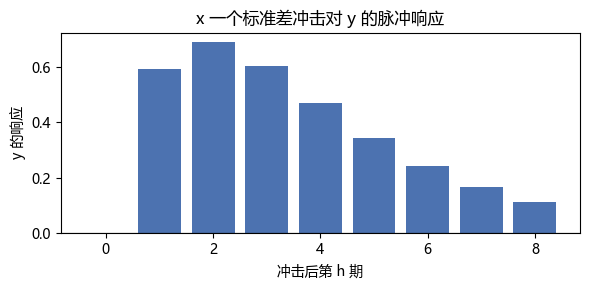

第 1 期响应 0.594 第 4 期响应 0.469


In [4]:

import io
from contextlib import redirect_stdout

import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests

rng = np.random.default_rng(4303)
n, burn = 320, 100
A = np.array([[0.60, 0.00], [0.45, 0.55]])
shock = rng.normal(scale=[0.6, 0.8], size=(n + burn, 2))
z = np.zeros((n + burn, 2))
for t in range(1, n + burn):
    z[t] = A @ z[t - 1] + shock[t]
z = z[burn:]
x, y = z[:, 0], z[:, 1]
data = np.column_stack([x, y])

res = VAR(data).fit(maxlags=6, ic="aic")
print("VAR 阶数", res.k_ar)
buf = io.StringIO()
with redirect_stdout(buf):
    g_xy = grangercausalitytests(np.column_stack([y, x]), maxlag=3)
    g_yx = grangercausalitytests(np.column_stack([x, y]), maxlag=3)
print("x→y p 值", [round(float(g_xy[k][0]["ssr_ftest"][1]), 4) for k in (1, 2, 3)])
print("y→x p 值", [round(float(g_yx[k][0]["ssr_ftest"][1]), 4) for k in (1, 2, 3)])

irf = res.irf(8)
resp = irf.irfs[:, 1, 0]
plt.figure(figsize=(6, 3))
plt.bar(range(9), resp, color="#4c72b0")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("冲击后第 h 期")
plt.ylabel("y 的响应")
plt.title("x 一个标准差冲击对 y 的脉冲响应")
plt.tight_layout()
plt.show()
print("第 1 期响应", round(float(resp[1]), 3), "第 4 期响应", round(float(resp[4]), 3))



**读数**：AIC 选出 1 阶；$x\to y$ 三阶 p 值都≈0，$y\to x$ 为 0.9648、0.7815、0.4287，与设定一致。脉冲响应第 1 期 0.594、第 4 期 0.469：冲击进入 $y$ 后有持续，但逐步衰减。注意 Granger 检验的方向取决于列顺序：`grangercausalitytests` 检验的是“**第二列**是否 Granger 引起**第一列**”，传参时别把列序搞反。

**常见错误**：

1. 把 Granger 当因果。它只是“预测增量”，不是结构方程。
2. 不检验滞后阶就报结果。阶数选错，结论可能翻转。
3. 对不平稳的水平值直接做 VAR。应先差分；若存在协整，用 VECM 或至少把协整关系放进模型。

**停下来想一想**：如果 $x$ 和 $y$ 都被同一个未观测的政策变量驱动，Granger 检验会给出什么结果？

<details><summary>对照你的思路</summary>

很可能双向都显著：政策变量先动，随后 $x$、$y$ 依次反应，滞后项之间出现“你领先我、我领先你”的模式。Granger 检验无法区分“$x$ 真的推动 $y$”还是“共同冲击按顺序到达”。要谈因果，仍然需要外生变动或识别假设（事件、政策断点、工具变量）。

</details>

---

## 6. 面板固定效应：把“个体差异”减掉

### 6.1 模型与偏误

$$y_{it}=\alpha_i+\beta x_{it}+\epsilon_{it}.$$

$\alpha_i$ 是不随时间变的个体效应（公司质地、品种特性、地区）。若 $\alpha_i$ 与 $x_{it}$ 相关，混合 OLS 把 $\alpha_i$ 塞进误差项，估计有偏——这就是面板版的遗漏变量偏误。本例里 $x$ 含 $0.6\alpha_i$，所以混合 OLS 把 beta 从 0.8 推到 1.097。

### 6.2 组内变换

$$\tilde y_{it}=y_{it}-\bar y_i,\qquad \tilde x_{it}=x_{it}-\bar x_i,\qquad
\hat\beta_{FE}=\frac{\sum_{i,t}\tilde x_{it}\tilde y_{it}}{\sum_{i,t}\tilde x_{it}^2}.$$

每个个体减去自己的时间均值，$\alpha_i$ 被消掉。代价是：所有不随时间变的变量也一起被消掉，无法估计它们。

### 6.3 手算

两个个体、各两期。A：$x=(1,2)$、$y=(3,5)$；B：$x=(10,11)$、$y=(11,13)$。

组内去均值后 A：$\tilde x=(-0.5,0.5)$、$\tilde y=(-1,1)$；B 相同。于是

$$\hat\beta_{FE}=\frac{2\times(0.5\times1)}{4\times0.25}=2.0.$$

混合 OLS：$\bar x=6$、$\bar y=8$，$\sum(x-\bar x)(y-\bar y)=74$，$\sum(x-\bar x)^2=82$，得到 $74/82\approx0.902$。**同一个数据，混合 0.90、固定效应 2.0**，差别全在个体效应。

### 6.4 代码：混合 OLS vs 固定效应

用 numpy 手工做组内变换和按个体聚类的标准误，不依赖面板专用包，便于看清每一步。



pooled beta 1.097 se 0.031
FE beta 0.781 cluster se 0.019
组内 R2 0.718


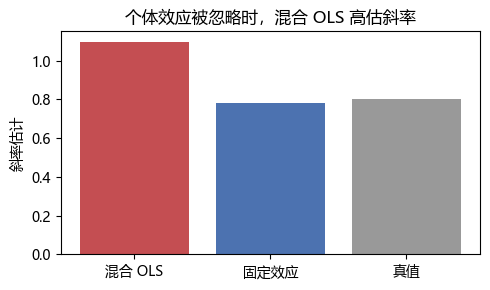

In [5]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(4304)
N, T = 12, 60
beta_true = 0.8
alpha_i = rng.normal(0.0, 0.8, size=N)
x = np.zeros((N, T))
y = np.zeros((N, T))
for i in range(N):
    for t in range(T):
        x[i, t] = 0.6 * alpha_i[i] + rng.normal(0.0, 1.0)
        y[i, t] = 1.0 + beta_true * x[i, t] + alpha_i[i] + rng.normal(0.0, 0.5)

Xp = np.column_stack([np.ones(N * T), x.ravel()])
beta_pool = np.linalg.lstsq(Xp, y.ravel(), rcond=None)[0]
res_pool = y.ravel() - Xp @ beta_pool
s2 = res_pool @ res_pool / (N * T - 2)
se_pool = np.sqrt((s2 * np.linalg.inv(Xp.T @ Xp))[1, 1])

xw = x - x.mean(axis=1, keepdims=True)
yw = y - y.mean(axis=1, keepdims=True)
beta_fe = float(xw.ravel() @ yw.ravel() / (xw.ravel() @ xw.ravel()))
res_fe = yw.ravel() - beta_fe * xw.ravel()
Xw = xw.ravel()[:, None]
meat = np.zeros((1, 1))
for i in range(N):
    score = Xw.reshape(N, T)[i] * res_fe.reshape(N, T)[i]
    meat += score[:, None].T @ score[:, None]
bread = np.linalg.inv(Xw.T @ Xw)
se_fe = float(np.sqrt((bread @ meat @ bread * (N / (N - 1)))[0, 0]))

print("pooled beta", round(float(beta_pool[1]), 3), "se", round(float(se_pool), 3))
print("FE beta", round(beta_fe, 3), "cluster se", round(se_fe, 3))
print("组内 R2", round(1 - res_fe @ res_fe / (yw.ravel() @ yw.ravel()), 3))

plt.figure(figsize=(5, 3))
plt.bar(["混合 OLS", "固定效应", "真值"], [float(beta_pool[1]), beta_fe, beta_true],
        color=["#c44e52", "#4c72b0", "#999999"])
plt.ylabel("斜率估计")
plt.title("个体效应被忽略时，混合 OLS 高估斜率")
plt.tight_layout()
plt.show()



**读数**：混合 OLS 的 beta=1.097（标准误 0.031），固定效应 beta=0.781（聚类标准误 0.019），真值 0.8；组内 R²=0.718。混合 OLS 把“个体效应高的组同时 x 也高”误当成 x 的作用，斜率被系统高估约 37%。图里三根柱子的差距就是偏误本身。

**常见错误**：

1. 不做组内变换，直接混合回归，然后解释“x 的效应”。
2. 做完固定效应还用普通标准误。个体内残差通常相关，要按个体聚类。
3. 把固定效应当因果。它只去掉不随时间变的混淆因素；随时间变的遗漏变量、反向因果照样存在。
4. 把时不变变量（行业、品种）放进固定效应模型，然后奇怪它为什么被“吸收”。

**停下来想一想**：固定效应能消除“公司文化”这类不随时间变的因素，但能不能消除“今年突然换了管理层”？

<details><summary>对照你的思路</summary>

不能。固定效应只减掉每个个体的时间均值，任何随时间变化的因素（换管理层、政策变化、行业景气切换）都还在误差项里。如果这些因素与 $x$ 同期相关，FE 估计仍然有偏。要处理时变混淆，需要加控制变量、事件研究、IV 或 DID。

</details>

---

## 7. IV / 2SLS 与 DID：想讲因果，先找外生变动

### 7.1 内生性

$$y=\beta x+u,\qquad \mathrm{Cov}(x,u)\neq0.$$

此时 OLS 的 $\hat\beta$ 收敛到 $\beta+\mathrm{Cov}(x,u)/\mathrm{Var}(x)$，偏误方向和大小都不知道。常见来源：遗漏变量、反向因果、测量误差。

### 7.2 2SLS

找一个工具变量 $z$，满足两个条件：

- **相关性**：$z$ 与 $x$ 相关（一阶段 $x=\pi z+v$ 的系数显著）；
- **外生性**：$z$ 与 $u$ 不相关（不可直接检验，只能靠制度/逻辑论证）。

两阶段：

$$x=\pi z+v\quad\Rightarrow\quad\hat x,\qquad
y=\beta\hat x+u\quad\Rightarrow\quad
\hat\beta_{2SLS}=(X'P_ZX)^{-1}X'P_Zy,\quad P_Z=Z(Z'Z)^{-1}Z'.$$

**公式拆解**
- **符号**：$y=\beta x+u$ 是结构方程且 $x$ 内生，$z$ 是工具变量，$P_Z=Z(Z'Z)^{-1}Z'$ 是投影矩阵，$\hat x=P_Zx$ 是一阶段拟合值，$\hat\beta_{2SLS}$ 是两阶段估计。
- **结构**：$P_Z$ 把 $x$ 拆成工具变量能解释的外生部分 $\hat x$ 和含内生性的残差，2SLS 只用外生部分解释 $y$，等于把与误差相关的部分扔掉。
- **代入**：本章真值 1.5、OLS 估到 2.091（偏误约 +0.59）、2SLS 估到 1.602，一阶段 $F=166.5$ 远高于 10，说明工具不弱。
- **边界**：弱工具（$F<10$）时偏误与标准误都大，工具外生性不可直接检验、只能靠制度论证，异方差下还要稳健标准误。
- **用途**：处理遗漏变量、测量误差与反向因果的常用识别手段；它不是万能药，找不到合格工具时 2SLS 比 OLS 更糟。

一阶段 F 的经验门槛是 10，但它只是“弱工具”的下限，不是安全线；F 很高也不代表外生性成立。

### 7.3 DID（双重差分）

$$y_{it}=\alpha+\gamma G_i+\delta T_t+\tau\,G_iT_t+\epsilon_{it}.$$

$\hat\tau=(\bar y_{处理,后}-\bar y_{处理,前})-(\bar y_{对照,后}-\bar y_{对照,前})$。关键假设是**平行趋势**：如果没有处理，两组的变化趋势应当相同。处理时点内生化、预期效应、组间构成变化都会破坏它。

### 7.4 手算

2SLS：真值 $\beta=1.5$。因为 $x$ 与遗漏变量 $u$ 正相关，OLS 估到 2.091；用工具变量后 2SLS 估到 1.602，接近真值。一阶段 F=166.5，远超 10。

DID：真值 $\tau=1.2$。对照组前后差 0.421，处理组前后差 1.581，差值 $1.581-0.421=1.16$，与回归里的交互项系数一致（标准误 0.204）。

### 7.5 代码：2SLS 与 DID



In [6]:

import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(4305)
n = 600
u = rng.normal(size=n)            # 同时影响 x 与 y 的遗漏变量
z = rng.normal(size=n)            # 工具变量
x = 0.7 * u + 0.5 * z + rng.normal(scale=0.7, size=n)
y = 1.0 + 1.5 * x + 1.0 * u + rng.normal(scale=0.5, size=n)

ols = sm.OLS(y, sm.add_constant(x)).fit()
first = sm.OLS(x, sm.add_constant(z)).fit()
Xh = np.column_stack([np.ones(n), first.fittedvalues])
tsls = np.linalg.lstsq(Xh, y, rcond=None)[0]
print("OLS beta", round(float(ols.params[1]), 3), "2SLS beta", round(float(tsls[1]), 3))
print("一阶段 F", round(float(first.fvalue), 1), "R2", round(float(first.rsquared), 3))

n2 = 400
grp = rng.integers(0, 2, size=n2)
post = rng.integers(0, 2, size=n2)
tau = 1.2
y2 = 2.0 + 0.8 * grp + 0.5 * post + tau * grp * post + rng.normal(scale=1.0, size=n2)
Xd = np.column_stack([np.ones(n2), grp, post, grp * post])
bd = np.linalg.lstsq(Xd, y2, rcond=None)[0]
res2 = y2 - Xd @ bd
s2 = res2 @ res2 / (n2 - 4)
cov_d = s2 * np.linalg.inv(Xd.T @ Xd)
print("DID 系数", round(float(bd[3]), 3), "se", round(float(np.sqrt(cov_d[3, 3])), 3))
print("对照组前后差", round(float(bd[2]), 3), "处理组前后差", round(float(bd[2] + bd[3]), 3))


OLS beta 2.091 2SLS beta 1.602
一阶段 F 166.5 R2 0.218
DID 系数 1.16 se 0.204
对照组前后差 0.421 处理组前后差 1.581



**读数**：OLS 的 beta=2.091，被遗漏变量 $u$ 推高；2SLS 的 beta=1.602，真值 1.5，偏误从 0.59 降到 0.10。一阶段 F=166.5、R²=0.218，工具不弱。DID 交互项 1.16，与手算的“处理组差值减对照组差值”完全一致；标准误 0.204 说明这个效应在统计上站得住。

**常见错误**：

1. 弱工具。一阶段 F 很低时，2SLS 比 OLS 偏得更多、标准误更大。
2. 把“工具变量外生”当默认。相关性可以检验，外生性不能；要靠制度、时间、逻辑来论证。
3. DID 不查平行趋势。至少画处理前趋势图，或做事件研究。
4. 用 2SLS 的 R² 判断模型好坏。2SLS 的 R² 没有 OLS 那种解释力。

**停下来想一想**：工具有效性中的“外生性”为什么无法用数据直接检验？

<details><summary>对照你的思路</summary>

外生性要求 $z$ 与 $u$ 不相关，但 $u$ 是不可观测的误差项，我们只能看到残差。若用残差去检验，等于先假定模型估计正确，循环论证。所以只能靠制度背景、自然实验、时间顺序来论证“工具只通过 x 影响 y”。这也是 IV 研究最容易被质疑的地方。

</details>

---

## 8. 模型诊断：交付前至少过一遍

### 8.1 五类诊断

| 诊断 | 看什么 | 工具 |
|---|---|---|
| 残差自相关 | LB 检验、ACF | `acorr_ljungbox`、HAC |
| 异方差 | 残差 vs 拟合值、BP 检验 | `het_breuschpagan`、稳健标准误 |
| 函数形式 | 残差是否有形状、RESET | 加二次项、换设定 |
| 异常值/突变 | 子样本稳定性、断点 | 滚动回归、Chow 检验 |
| 多重共线性 | VIF、系数符号稳定性 | 相关矩阵、VIF |

### 8.2 交付清单

- [ ] 平稳性：含单位根吗？差分还是协整？
- [ ] 标准误：异方差/自相关/聚类，报的是哪一种？
- [ ] 函数形式：残差还有没有可利用的结构？
- [ ] 异常值/结构突变：换子样本结论是否翻转？
- [ ] 多重共线性：系数符号是否符合经济直觉？
- [ ] 识别：外生性来自哪里？一阶段 F 多少？平行趋势查了吗？
- [ ] 稳健性：换窗口、换控制、换标准误，结论是否稳定？
- [ ] 样本外：留出最后一段，不要用全样本调参。

---

## 本章小结

### 一张表

| 主题 | 公式/做法 | 用在哪 |
|---|---|---|
| OLS | $(X'X)^{-1}X'y$ | 条件均值关系 |
| HAC | Newey–West 三明治 | 残差自相关时的标准误 |
| ADF | $\Delta y_t=\alpha+\rho y_{t-1}+\cdots$ | 单位根 |
| 协整 | 残差平稳 | 配对/价差交易 |
| 半衰期 | $\ln0.5/\ln\phi$ | 均值回归速度 |
| VAR | 多变量滞后系统 | 领先—滞后 |
| Granger | 滞后项联合检验 | 预测增量 |
| 面板 FE | 组内变换 | 去掉个体效应 |
| 2SLS | $(X'P_ZX)^{-1}X'P_Zy$ | 内生性 |
| DID | 交互项 $\tau$ | 政策/事件效应 |

### 八句话

1. 系数回答“多少”，标准误回答“信不信”。
2. 自相关残差会让普通 t 值虚高，HAC 是解药。
3. 价格不平稳、收益平稳；水平值回归前先查单位根。
4. 高 R² 可能是伪回归，残差平稳才是真关系。
5. 协整给“能不能配”，半衰期给“多久回来”。
6. Granger 是预测性因果，不是结构因果。
7. 固定效应去掉不随时间变的混淆，去不掉时变混淆。
8. IV 靠外生、DID 靠平行趋势——两者都不能靠 p 值证明。

---

## 本章习题

**1.** 一元回归中 $\hat\beta=\sum(x-\bar x)(y-\bar y)/\sum(x-\bar x)^2$。给定 $x=(1,2,3,4)$、$y=(2,4,5,4)$，求 $\hat\beta$ 和 $\hat\alpha$。

**2.** 为什么 AR(1) 残差会让普通 OLS 的 t 值虚高？HAC 修正的是哪一部分？

**3.** 价格 ADF 的 p=0.986、收益 ADF 的 p≈0，分别说明什么？能不能因此说“价格一定随机漫步”？

**4.** 一对价格协整 p=0.0002、半衰期 5 天；另一对协整 p=0.01、半衰期 60 天。做配对交易时更要警惕哪一对？

**5.** 伪回归的 R²=0.587，协整 p=0.25。这两个数字矛盾吗？为什么？

**6.** 面板模型 $y_{it}=\alpha_i+\beta x_{it}+\epsilon_{it}$，若 $\alpha_i$ 与 $x_{it}$ 正相关，混合 OLS 的 beta 会高估还是低估？固定效应怎么修正？

**7.** 2SLS 中一阶段 F=3，OLS beta=0.4、2SLS beta=1.8。这两个估计哪个更可信？为什么？

**8.** DID 估计的处理效应是 1.16，但处理组在政策前一年已经开始加速增长。这个估计可能存在什么偏误？应该补什么检验？

<details><summary>参考答案</summary>

**1.** $\bar x=2.5$、$\bar y=3.75$；分子 3.5、分母 5，$\hat\beta=0.7$；$\hat\alpha=3.75-0.7\times2.5=2.0$。

**2.** 残差正相关意味着相邻观测信息重复，有效样本量小于名义样本量；普通标准误按独立样本算，分母偏小、t 值偏大。HAC 用自协方差加权和估计长期方差，把重复信息扣掉。

**3.** 价格不能拒绝单位根（非平稳），收益拒绝单位根（平稳）。不能因此断言“价格一定随机漫步”：p 值大只是不拒绝，可能是检验力不足，也可能是接近单位根的平稳过程；还要看经济逻辑与更长样本。

**4.** 第二对（半衰期 60 天）更危险。半衰期越长，资金占用越久、期间结构变化和成本越高，参数不稳定的暴露也越长；5 天的价差更容易在短时间内完成回归。

**5.** 不矛盾。R² 衡量样本内线性拟合，伪回归下随机漫步也能得到不低的 R²；协整 p 检验残差是否平稳，p=0.25 说明没有稳定长期关系。高 R² + 高协整 p，正是伪回归的典型组合。

**6.** 高估（本例从 0.8 估到 1.097）。固定效用组内变换，每个个体减去自己的时间均值，$\alpha_i$ 被消掉，再用组内离差回归。

**7.** 都不太可信。一阶段 F=3 是弱工具，2SLS 的偏误可能比 OLS 还大、标准误也更大；正确做法是换工具、用弱工具稳健推断，或承认识别不足，而不是挑一个好看的结果。

**8.** 处理组在政策前已加速增长，违反平行趋势，DID 会把“原本就在发生的趋势”算成政策效应，估计偏高。应做事件研究/前期趋势检验，或改用合成控制、加入组别时间趋势、寻找更干净的处理时点。

</details>

---

## 参考资料

- Wooldridge, J. M. *Introductory Econometrics: A Modern Approach*（回归、面板、IV、DID 的标准教材）。
- Hamilton, J. D. *Time Series Analysis*（单位根、协整、VAR）。
- Newey, W. K. & West, K. D. (1987). A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix.
- Engle, R. F. & Granger, C. W. J. (1987). Co-integration and Error Correction.
- Granger, C. W. J. (1969). Investigating Causal Relations by Econometric Models and Cross-spectral Methods.
- Angrist, J. D. & Pischke, J.-S. *Mostly Harmless Econometrics*（IV、DID 的直觉）。
- statsmodels 文档：<https://www.statsmodels.org/stable/index.html>
